[ 4.79696597  0.37649774 -0.0289188 ]
[0.05615904 0.01102002 0.03887829]
Fitted rate constant b: 0.3765 ± 0.0110 s^-1
Calculated time constant tau: 2.6561 ± 0.0777 s
chi squared truncated exponential: 8.791126526238457e-06
chi squared exponential: 0.8614617798081771
reduced chi squared truncated exponential: 0.013653220025088352
reduced chi squared exponential: 0.0957179755342419


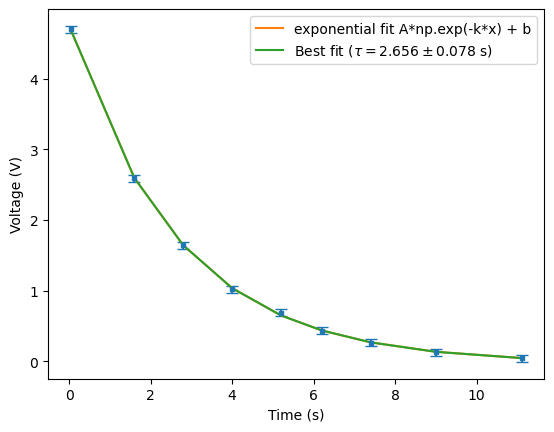

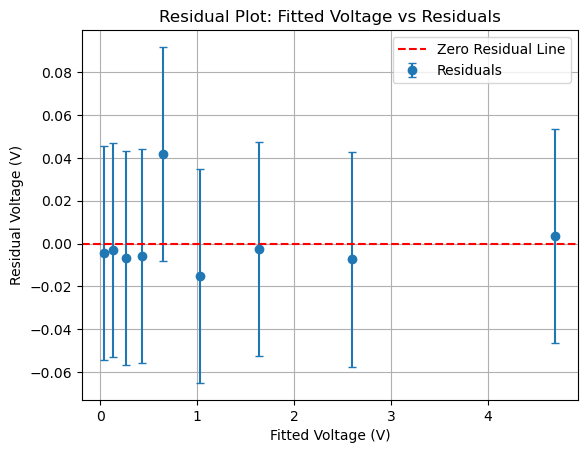

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#data
time, voltage, unc = np.loadtxt("PHY244 Time constant data - Sheet1.csv", skiprows = 1, delimiter = ',', comments = '#', unpack = True)
#unc: uncertainty

#exponential model
def voltage_variation(x, A, k, b):
    return A * np.exp(-k * x) + b

#fit model to data
popt, pcov = curve_fit(voltage_variation,
                    time,
                    voltage,
                    sigma = unc,
                    absolute_sigma = True,
                    p0=[1.0, 0.1, 0.0])

pstd = (np.sqrt(np.diag(pcov)))
print(popt)
print(pstd)

#plot data
plt.errorbar(time, voltage, yerr = unc, ls = '', marker = 's',markersize=3,capsize=4,capthick=1)

#plot curve fit
plt.plot(time, voltage_variation(time, *popt), label = "exponential fit A*np.exp(-k*x) + b")

b_val = popt[1]
b_unc = pstd[1]

tau = 1.0 / b_val
tau_unc = b_unc / (b_val**2)

print(f"Fitted rate constant b: {b_val:.4f} ± {b_unc:.4f} s^-1")
print(f"Calculated time constant tau: {tau:.4f} ± {tau_unc:.4f} s")

plt.plot(time,voltage_variation(time, *popt),label=f"Best fit ($\\tau = {tau:.3f} \\pm {tau_unc:.3f}\\text{{ s}}$)")

#decorate the plot
plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.legend()

def chi_squared(data, model_values, uncertainty):
    difference = data - model_values
    diff_unc = difference / uncertainty
    diff_squared = diff_unc**2
    sum_diff_squared = np.sum(diff_squared)
    return sum_diff_squared

def reduced_chi_squared(data, model_values, uncertainty):
    denominator = len(data)
    return chi_squared(data, model_values, uncertainty) / denominator

exponential_model_data = voltage_variation(time, *popt)

exponential_model_data_truncated = voltage_variation(time[:2], *popt)

print("chi squared truncated exponential:", chi_squared(voltage[:2], exponential_model_data_truncated, voltage[:2]))
print("chi squared exponential:", chi_squared(voltage, exponential_model_data, unc))
print("reduced chi squared truncated exponential:", reduced_chi_squared(voltage[:2], exponential_model_data_truncated, unc[:2]))
print("reduced chi squared exponential:", reduced_chi_squared(voltage, exponential_model_data, unc))

#residuals
fitted_voltage = voltage_variation(time, *popt)
residuals = voltage - fitted_voltage

plt.figure()
plt.errorbar(fitted_voltage, residuals, yerr=unc, fmt="o", capsize=3, label="Residuals")

#add a reference line at y = 0
plt.axhline(0, color="red", linestyle="--", label="Zero Residual Line")

#decorate the plot
plt.xlabel("Fitted Voltage (V)")
plt.ylabel("Residual Voltage (V)")
plt.title("Residual Plot: Fitted Voltage vs Residuals")
plt.legend()
plt.grid(True)
plt.show()